# Loan Recovery Prediction Using Machine Learning

## Project Objective

Build classification models to predict the likelihood of loan recovery,
evaluate model performance using Recall and ROC-AUC metrics, and provide
explainable insights to support optimized debt recovery strategies.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
import pandas as pd

df = pd.read_csv("../data/loan_recovery_dataset_raw.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (25000, 19)


In [6]:
df

,customer_id,customer_name,loan_id,age,income,employment_type,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,employment_years,collateral_value,loan_purpose,contact_success_rate,loan_recovered
0,CUST006869,Ishaan Kapoor,LN0006869,50,94000.0,Salaried,641.0,480000.0,48,7.84,0.302,1,0.0,0.0,14,355000.0,Vehicle,0.688,1
1,CUST024017,Akash Mirza,LN0024017,40,61000.0,Salaried,545.0,155000.0,48,11.51,0.206,0,1.0,2.0,6,5000.0,Personal,0.400,1
2,CUST009669,Naveen Mishra,LN0009669,60,141500.0,Salaried,740.0,1075000.0,18,8.10,0.190,0,0.0,0.0,28,595000.0,Vehicle,0.903,1
3,CUST013641,Imran Saxena,LN0013641,37,48500.0,Self-employed,602.0,195000.0,18,9.33,0.275,2,0.0,0.0,2,135000.0,Vehicle,0.486,0
4,CUST014019,Dev Gowda,LN0014019,31,45000.0,Salaried,669.0,220000.0,60,9.99,0.280,2,0.0,1.0,8,25000.0,Personal,0.506,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,CUST021576,Rehan Pawar,LN0021576,25,39500.0,Salaried,618.0,385000.0,60,9.80,0.209,1,1.0,0.0,5,370000.0,Business,0.383,0
24996,CUST005391,Abhinav Hegde,LN0005391,40,77500.0,Contract,663.0,485000.0,48,9.58,0.209,1,0.0,1.0,10,65000.0,Personal,0.502,1
24997,CUST000861,Amit Patil,LN0000861,37,77000.0,NaN,579.0,1105000.0,72,9.63,0.172,0,2.0,4.0,7,1395000.0,Home,0.310,0
24998,CUST015796,Harini Kapoor,LN0015796,38,84500.0,Salaried,558.0,610000.0,12,10.18,0.307,3,4.0,5.0,12,55000.0,Education,0.138,0


In [7]:
df.head()

,customer_id,customer_name,loan_id,age,income,employment_type,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,employment_years,collateral_value,loan_purpose,contact_success_rate,loan_recovered
0,CUST006869,Ishaan Kapoor,LN0006869,50,94000.0,Salaried,641.0,480000.0,48,7.84,0.302,1,0.0,0.0,14,355000.0,Vehicle,0.688,1
1,CUST024017,Akash Mirza,LN0024017,40,61000.0,Salaried,545.0,155000.0,48,11.51,0.206,0,1.0,2.0,6,5000.0,Personal,0.400,1
2,CUST009669,Naveen Mishra,LN0009669,60,141500.0,Salaried,740.0,1075000.0,18,8.10,0.190,0,0.0,0.0,28,595000.0,Vehicle,0.903,1
3,CUST013641,Imran Saxena,LN0013641,37,48500.0,Self-employed,602.0,195000.0,18,9.33,0.275,2,0.0,0.0,2,135000.0,Vehicle,0.486,0
4,CUST014019,Dev Gowda,LN0014019,31,45000.0,Salaried,669.0,220000.0,60,9.99,0.280,2,0.0,1.0,8,25000.0,Personal,0.506,1


In [8]:
df.tail()

,customer_id,customer_name,loan_id,age,income,employment_type,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,employment_years,collateral_value,loan_purpose,contact_success_rate,loan_recovered
24995,CUST021576,Rehan Pawar,LN0021576,25,39500.0,Salaried,618.0,385000.0,60,9.80,0.209,1,1.0,0.0,5,370000.0,Business,0.383,0
24996,CUST005391,Abhinav Hegde,LN0005391,40,77500.0,Contract,663.0,485000.0,48,9.58,0.209,1,0.0,1.0,10,65000.0,Personal,0.502,1
24997,CUST000861,Amit Patil,LN0000861,37,77000.0,NaN,579.0,1105000.0,72,9.63,0.172,0,2.0,4.0,7,1395000.0,Home,0.310,0
24998,CUST015796,Harini Kapoor,LN0015796,38,84500.0,Salaried,558.0,610000.0,12,10.18,0.307,3,4.0,5.0,12,55000.0,Education,0.138,0
24999,CUST023655,Ananya Desai,LN0023655,36,70500.0,Salaried,694.0,365000.0,36,8.99,0.191,1,0.0,0.0,5,80000.0,Personal,0.639,1


In [9]:
df.shape

(25000, 19)

In [10]:
df.columns

Index(['customer_id', 'customer_name', 'loan_id', 'age', 'income',
       'employment_type', 'credit_score', 'loan_amount', 'loan_term_months',
       'interest_rate', 'debt_to_income', 'existing_loans',
       'previous_defaults', 'payment_delays', 'employment_years',
       'collateral_value', 'loan_purpose', 'contact_success_rate',
       'loan_recovered'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           25000 non-null  object 
 1   customer_name         25000 non-null  object 
 2   loan_id               25000 non-null  object 
 3   age                   25000 non-null  int64  
 4   income                24550 non-null  float64
 5   employment_type       24696 non-null  object 
 6   credit_score          24626 non-null  float64
 7   loan_amount           24750 non-null  float64
 8   loan_term_months      25000 non-null  int64  
 9   interest_rate         25000 non-null  float64
 10  debt_to_income        24552 non-null  float64
 11  existing_loans        25000 non-null  int64  
 12  previous_defaults     24703 non-null  float64
 13  payment_delays        24619 non-null  float64
 14  employment_years      25000 non-null  int64  
 15  collateral_value   

In [12]:
df.describe()

,age,income,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,employment_years,collateral_value,contact_success_rate,loan_recovered
count,25000.000000,2.455000e+04,24626.000000,2.475000e+04,25000.00000,25000.000000,24552.000000,25000.000000,24703.00000,24619.000000,25000.000000,2.470500e+04,24626.000000,25000.000000
mean,37.108640,7.391621e+04,616.278080,5.312857e+05,42.38904,8.980579,0.232568,1.380520,0.84512,2.127219,9.910400,3.696284e+05,0.464928,0.650040
std,8.736799,5.605786e+04,51.590739,6.335776e+05,17.92829,1.395894,0.080433,1.243522,1.08320,2.328682,5.674326,5.001318e+05,0.164049,0.476967
min,17.000000,-5.000000e+03,250.000000,-1.000000e+04,12.00000,0.500000,-0.100000,-2.000000,-1.00000,-2.000000,-3.000000,-5.000000e+04,-0.200000,0.000000
25%,31.000000,5.050000e+04,582.000000,2.750000e+05,36.00000,8.130000,0.179000,0.000000,0.00000,1.000000,6.000000,4.500000e+04,0.363000,0.000000
50%,37.000000,7.150000e+04,616.000000,4.300000e+05,36.00000,8.940000,0.229000,1.000000,1.00000,2.000000,10.000000,2.050000e+05,0.476000,1.000000
75%,43.000000,9.300000e+04,650.000000,6.650000e+05,60.00000,9.790000,0.281000,2.000000,1.00000,3.000000,13.000000,5.300000e+05,0.578000,1.000000
max,85.000000,2.500000e+06,950.000000,2.500000e+07,84.00000,45.000000,1.500000,20.000000,12.00000,40.000000,50.000000,1.500000e+07,1.500000,1.000000


In [13]:
df.isnull().sum()

customer_id               0
customer_name             0
loan_id                   0
age                       0
income                  450
employment_type         304
credit_score            374
loan_amount             250
loan_term_months          0
interest_rate             0
debt_to_income          448
existing_loans            0
previous_defaults       297
payment_delays          381
employment_years          0
collateral_value        295
loan_purpose            251
contact_success_rate    374
loan_recovered            0
dtype: int64

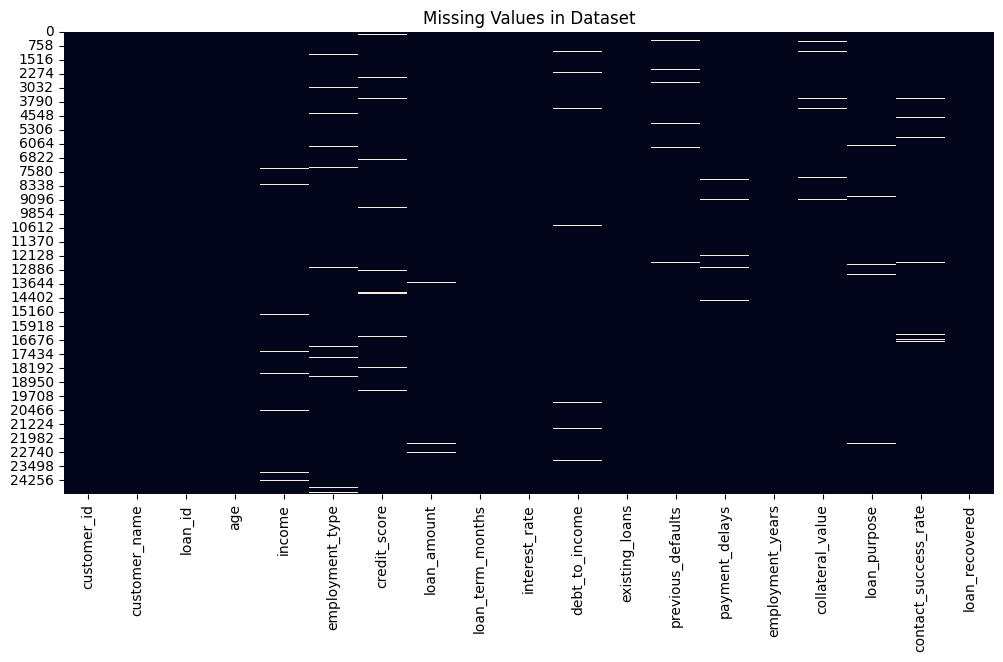

In [14]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Dataset")
plt.show()

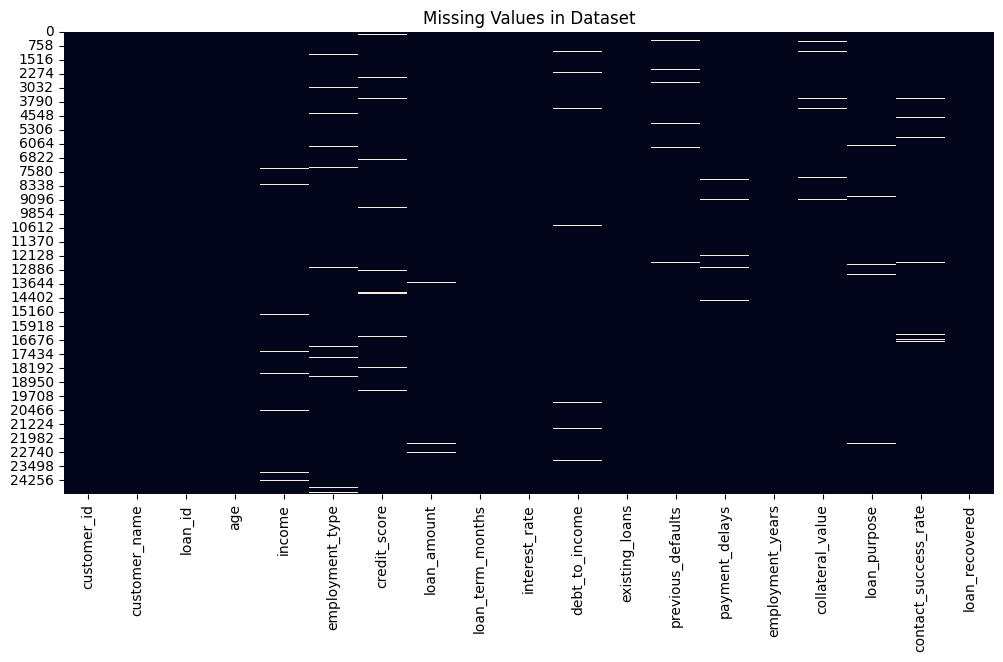

In [15]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Dataset")
plt.show()

In [16]:
df.duplicated().sum()

np.int64(300)

In [17]:
df["employment_type"].value_counts(dropna=False)

employment_type
Salaried           11766
Self-employed       4935
Business            4074
Contract            2493
Unemployed          1205
NaN                  304
salaried              36
 Salaried             31
SALARIED              26
 Self-employed        24
BUSINESS              19
SELF-EMPLOYED         15
self-employed         13
business              11
CONTRACT              10
 Business             10
contract               9
unemployed             5
 Contract              5
 Unemployed            5
UNEMPLOYED             4
Name: count, dtype: int64

In [18]:
df["loan_purpose"].value_counts(dropna=False)

loan_purpose
Personal       7004
Home           5501
Vehicle        5432
Business       3627
Education      2963
NaN             251
 Home            23
 Personal        23
HOME             20
PERSONAL         20
home             20
vehicle          17
personal         15
business         14
VEHICLE          14
BUSINESS         13
 Vehicle         13
 Business         9
EDUCATION         8
education         7
 Education        6
Name: count, dtype: int64

In [19]:
df["age"].describe()

count    25000.000000
mean        37.108640
std          8.736799
min         17.000000
25%         31.000000
50%         37.000000
75%         43.000000
max         85.000000
Name: age, dtype: float64

In [20]:
df["income"].describe()

count    2.455000e+04
mean     7.391621e+04
std      5.605786e+04
min     -5.000000e+03
25%      5.050000e+04
50%      7.150000e+04
75%      9.300000e+04
max      2.500000e+06
Name: income, dtype: float64

In [21]:
df["credit_score"].describe()

count    24626.000000
mean       616.278080
std         51.590739
min        250.000000
25%        582.000000
50%        616.000000
75%        650.000000
max        950.000000
Name: credit_score, dtype: float64

In [22]:
df["credit_score"].describe()

count    24626.000000
mean       616.278080
std         51.590739
min        250.000000
25%        582.000000
50%        616.000000
75%        650.000000
max        950.000000
Name: credit_score, dtype: float64

In [23]:
df["debt_to_income"].describe()

count    24552.000000
mean         0.232568
std          0.080433
min         -0.100000
25%          0.179000
50%          0.229000
75%          0.281000
max          1.500000
Name: debt_to_income, dtype: float64

# 2. Data Cleaning

The raw dataset contains missing values, duplicate records,
inconsistent categorical values, and invalid numerical values.

The following preprocessing steps will be performed:

1. Remove duplicate records
2. Handle missing values
3. Standardize categorical variables
4. Detect and handle invalid numerical values
5. Detect and handle outliers

In [24]:
df_clean = df.copy()

print("Copy created successfully.")

Copy created successfully.


In [25]:
print("Duplicate rows before cleaning:", df_clean.duplicated().sum())

Duplicate rows before cleaning: 300


In [26]:
df_clean = df_clean.drop_duplicates()

print("Duplicate rows after cleaning:", df_clean.duplicated().sum())
print("New dataset shape:", df_clean.shape)

Duplicate rows after cleaning: 0
New dataset shape: (24700, 19)


In [27]:
print(df_clean["employment_type"].value_counts(dropna=False))

employment_type
Salaried           11614
Self-employed       4870
Business            4039
Contract            2471
Unemployed          1190
NaN                  296
salaried              35
 Salaried             31
SALARIED              26
 Self-employed        23
BUSINESS              19
SELF-EMPLOYED         14
self-employed         13
business              11
CONTRACT              10
 Business             10
contract               9
unemployed             5
 Contract              5
 Unemployed            5
UNEMPLOYED             4
Name: count, dtype: int64


In [28]:
print(df_clean["loan_purpose"].value_counts(dropna=False))

loan_purpose
Personal       6914
Home           5443
Vehicle        5368
Business       3586
Education      2922
NaN             247
 Home            23
 Personal        23
HOME             20
home             20
PERSONAL         19
vehicle          17
personal         15
business         14
BUSINESS         13
VEHICLE          13
 Vehicle         13
 Business         9
EDUCATION         8
education         7
 Education        6
Name: count, dtype: int64


In [29]:
df_clean["employment_type"] = (
    df_clean["employment_type"]
    .astype("string")
    .str.strip()
    .str.title()
)

df_clean["loan_purpose"] = (
    df_clean["loan_purpose"]
    .astype("string")
    .str.strip()
    .str.title()
)

In [30]:
print(df_clean["employment_type"].value_counts(dropna=False))

print(df_clean["loan_purpose"].value_counts(dropna=False))

employment_type
Salaried         11706
Self-Employed     4920
Business          4079
Contract          2495
Unemployed        1204
<NA>               296
Name: count, dtype: Int64
loan_purpose
Personal     6971
Home         5506
Vehicle      5411
Business     3622
Education    2943
<NA>          247
Name: count, dtype: Int64


## 2.1 Detecting Invalid Numerical Values

Numerical variables are checked against logical business constraints
before missing values and outliers are handled.

In [31]:
print("Invalid income values:", (df_clean["income"] <= 0).sum())

Invalid income values: 12


In [32]:
print("Invalid credit score values:",
      ((df_clean["credit_score"] < 300) | (df_clean["credit_score"] > 850)).sum())

Invalid credit score values: 25


In [33]:
print("Invalid DTI values:",
      ((df_clean["debt_to_income"] < 0) | (df_clean["debt_to_income"] > 1)).sum())

Invalid DTI values: 18


In [34]:
print("Invalid payment delay values:",
      (df_clean["payment_delays"] < 0).sum())

Invalid payment delay values: 8


In [35]:
print("Invalid previous default values:",
      (df_clean["previous_defaults"] < 0).sum())

Invalid previous default values: 4


In [36]:
print("Invalid employment years:",
      (df_clean["employment_years"] < 0).sum())

Invalid employment years: 6


In [37]:
print("Invalid contact success rates:",
      ((df_clean["contact_success_rate"] < 0) |
       (df_clean["contact_success_rate"] > 1)).sum())

Invalid contact success rates: 20


In [38]:
df_clean["age"].describe()

df_clean["loan_amount"].describe()

df_clean["interest_rate"].describe()

df_clean["payment_delays"].describe()

df_clean["collateral_value"].describe()

df_clean["contact_success_rate"].describe()

count    24330.000000
mean         0.464980
std          0.164096
min         -0.200000
25%          0.363000
50%          0.476000
75%          0.578000
max          1.500000
Name: contact_success_rate, dtype: float64

In [39]:
df_clean.loc[
    (df_clean["contact_success_rate"] < 0) |
    (df_clean["contact_success_rate"] > 1),
    "contact_success_rate"
] = np.nan

In [40]:
df_clean["contact_success_rate"].describe()

count    24310.000000
mean         0.464507
std          0.162316
min          0.000000
25%          0.363000
50%          0.476000
75%          0.578000
max          0.990000
Name: contact_success_rate, dtype: float64

In [41]:
df_clean["contact_success_rate"].isnull().sum()

np.int64(390)

In [42]:
df_clean["age"].describe()

df_clean["loan_amount"].describe()

df_clean["interest_rate"].describe()

df_clean["payment_delays"].describe()

count    24330.000000
mean         2.126963
std          2.330274
min         -2.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         40.000000
Name: payment_delays, dtype: float64

In [43]:
df_clean.loc[
    df_clean["employment_years"] < 0,
    "employment_years"
] = np.nan

In [44]:
print("Missing employment years:", df_clean["employment_years"].isnull().sum())
print("Minimum employment years:", df_clean["employment_years"].min())

Missing employment years: 6
Minimum employment years: 0.0


In [45]:
df_clean["existing_loans"].describe()

count    24700.00000
mean         1.38085
std          1.24341
min         -2.00000
25%          0.00000
50%          1.00000
75%          2.00000
max         20.00000
Name: existing_loans, dtype: float64

In [46]:
df_clean.loc[
    df_clean["existing_loans"] < 0,
    "existing_loans"
] = np.nan

In [47]:
print("Missing existing loans:", df_clean["existing_loans"].isnull().sum())
print("Minimum existing loans:", df_clean["existing_loans"].min())

Missing existing loans: 5
Minimum existing loans: 0.0


In [48]:
df_clean["previous_defaults"].describe()

count    24404.000000
mean         0.845476
std          1.084215
min         -1.000000
25%          0.000000
50%          1.000000
75%          1.000000
max         12.000000
Name: previous_defaults, dtype: float64

In [49]:
df_clean.loc[
    df_clean["previous_defaults"] < 0,
    "previous_defaults"
] = np.nan

In [50]:
print("Missing previous defaults:", df_clean["previous_defaults"].isnull().sum())
print("Minimum previous defaults:", df_clean["previous_defaults"].min())

Missing previous defaults: 300
Minimum previous defaults: 0.0


In [51]:
df_clean["age"].describe()

count    24700.000000
mean        37.115506
std          8.738342
min         17.000000
25%         31.000000
50%         37.000000
75%         43.000000
max         85.000000
Name: age, dtype: float64

In [52]:
df_clean.loc[
    (df_clean["age"] < 18) | (df_clean["age"] > 70),
    "age"
] = np.nan

In [53]:
print("Missing/invalid ages:", df_clean["age"].isnull().sum())
print("Minimum age:", df_clean["age"].min())
print("Maximum age:", df_clean["age"].max())

Missing/invalid ages: 22
Minimum age: 19.0
Maximum age: 65.0


In [54]:
df_clean["loan_amount"].describe()

count    2.445300e+04
mean     5.319611e+05
std      6.364520e+05
min     -1.000000e+04
25%      2.750000e+05
50%      4.300000e+05
75%      6.650000e+05
max      2.500000e+07
Name: loan_amount, dtype: float64

In [55]:
df_clean.loc[
    df_clean["loan_amount"] <= 0,
    "loan_amount"
] = np.nan

In [56]:
print("Missing/invalid loan amounts:", df_clean["loan_amount"].isnull().sum())
print("Minimum loan amount:", df_clean["loan_amount"].min())

Missing/invalid loan amounts: 256
Minimum loan amount: 50000.0


In [57]:
df_clean["interest_rate"].describe()

count    24700.000000
mean         8.980417
std          1.397144
min          0.500000
25%          8.130000
50%          8.940000
75%          9.790000
max         45.000000
Name: interest_rate, dtype: float64

In [58]:
df_clean.loc[
    (df_clean["interest_rate"] < 3) |
    (df_clean["interest_rate"] > 20),
    "interest_rate"
] = np.nan

In [59]:
print("Missing/invalid interest rates:", df_clean["interest_rate"].isnull().sum())
print("Minimum interest rate:", df_clean["interest_rate"].min())
print("Maximum interest rate:", df_clean["interest_rate"].max())

Missing/invalid interest rates: 25
Minimum interest rate: 6.5
Maximum interest rate: 14.0


In [60]:
df_clean.isnull().sum()

customer_id               0
customer_name             0
loan_id                   0
age                      22
income                  444
employment_type         296
credit_score            369
loan_amount             256
loan_term_months          0
interest_rate            25
debt_to_income          443
existing_loans            5
previous_defaults       300
payment_delays          370
employment_years          6
collateral_value        295
loan_purpose            247
contact_success_rate    390
loan_recovered            0
dtype: int64

In [61]:
numeric_columns = [
    "age",
    "income",
    "credit_score",
    "loan_amount",
    "loan_term_months",
    "interest_rate",
    "debt_to_income",
    "existing_loans",
    "previous_defaults",
    "payment_delays",
    "employment_years",
    "collateral_value",
    "contact_success_rate"
]

In [62]:
for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

In [63]:
categorical_columns = [
    "employment_type",
    "loan_purpose"
]

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].mode()[0]
    )

In [64]:
df_clean.isnull().sum()

customer_id             0
customer_name           0
loan_id                 0
age                     0
income                  0
employment_type         0
credit_score            0
loan_amount             0
loan_term_months        0
interest_rate           0
debt_to_income          0
existing_loans          0
previous_defaults       0
payment_delays          0
employment_years        0
collateral_value        0
loan_purpose            0
contact_success_rate    0
loan_recovered          0
dtype: int64

In [65]:
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


In [66]:
print("Employment Type:")
print(df_clean["employment_type"].value_counts())

print("\nLoan Purpose:")
print(df_clean["loan_purpose"].value_counts())

Employment Type:
employment_type
Salaried         12002
Self-Employed     4920
Business          4079
Contract          2495
Unemployed        1204
Name: count, dtype: Int64

Loan Purpose:
loan_purpose
Personal     7218
Home         5506
Vehicle      5411
Business     3622
Education    2943
Name: count, dtype: Int64


In [67]:
print(df_clean["loan_recovered"].value_counts())

loan_recovered
1    16055
0     8645
Name: count, dtype: int64


In [68]:
print(df_clean["loan_recovered"].value_counts(normalize=True) * 100)

loan_recovered
1    65.0
0    35.0
Name: proportion, dtype: float64


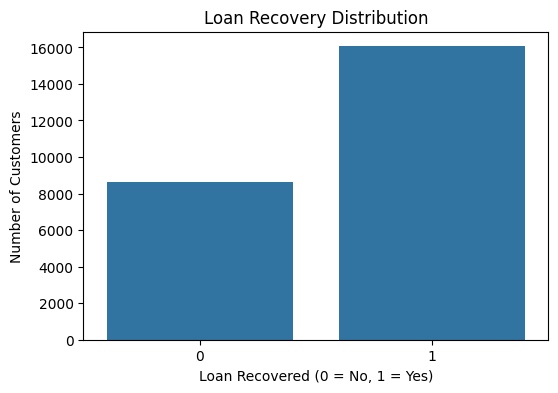

In [69]:
plt.figure(figsize=(6, 4))

sns.countplot(x="loan_recovered", data=df_clean)

plt.title("Loan Recovery Distribution")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

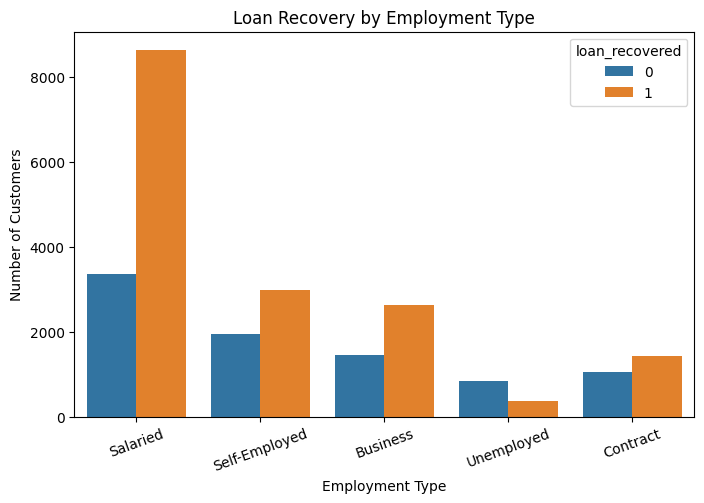

In [70]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x="employment_type",
    hue="loan_recovered",
    data=df_clean
)

plt.title("Loan Recovery by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.show()

In [71]:
recovery_by_employment = pd.crosstab(
    df_clean["employment_type"],
    df_clean["loan_recovered"],
    normalize="index"
) * 100

recovery_by_employment

loan_recovered,0,1
employment_type,,
Business,35.351802,64.648198
Contract,42.444890,57.555110
Salaried,28.020330,71.979670
Self-Employed,39.329268,60.670732
Unemployed,70.265781,29.734219


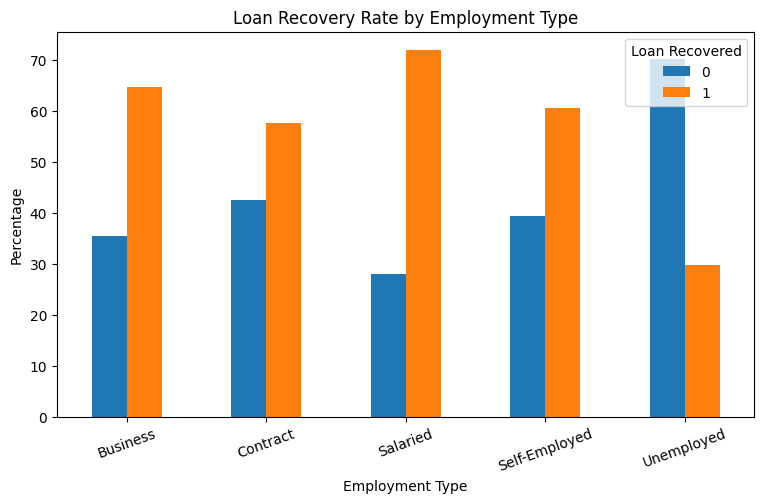

In [72]:
recovery_by_employment.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Loan Recovery Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Percentage")
plt.xticks(rotation=20)
plt.legend(title="Loan Recovered")

plt.show()

In [73]:
recovery_by_purpose = pd.crosstab(
    df_clean["loan_purpose"],
    df_clean["loan_recovered"],
    normalize="index"
) * 100

recovery_by_purpose

loan_recovered,0,1
loan_purpose,,
Business,33.903920,66.096080
Education,35.134217,64.865783
Home,36.451144,63.548856
Personal,35.743973,64.256027
Vehicle,33.191647,66.808353


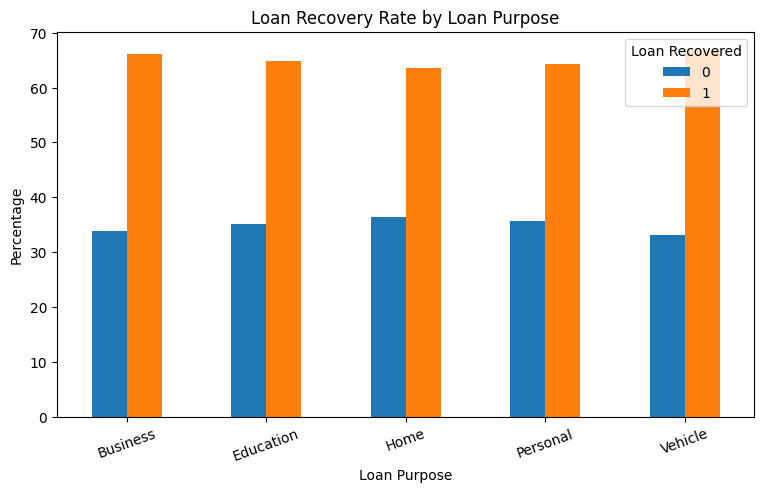

In [74]:
recovery_by_purpose.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Loan Recovery Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Percentage")
plt.xticks(rotation=20)
plt.legend(title="Loan Recovered")

plt.show()

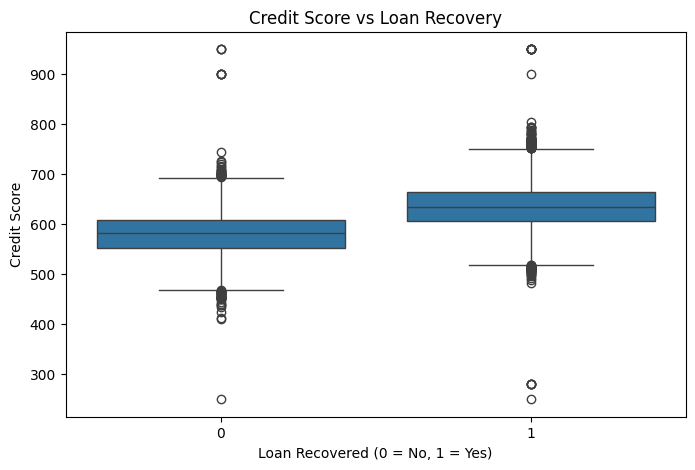

In [75]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="loan_recovered",
    y="credit_score",
    data=df_clean
)

plt.title("Credit Score vs Loan Recovery")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Credit Score")

plt.show()

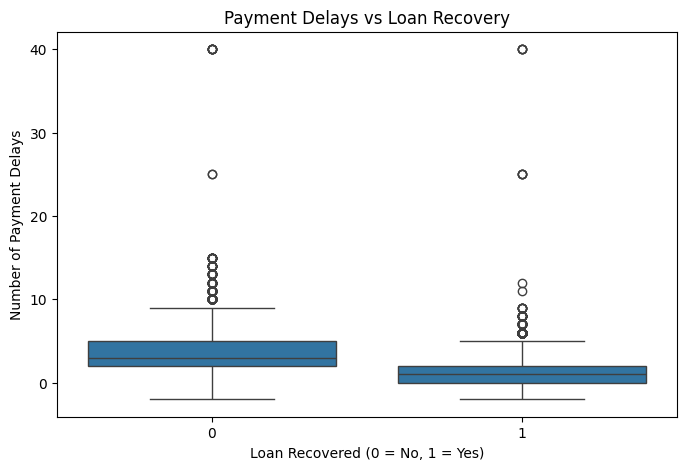

In [76]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="loan_recovered",
    y="payment_delays",
    data=df_clean
)

plt.title("Payment Delays vs Loan Recovery")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Number of Payment Delays")

plt.show()

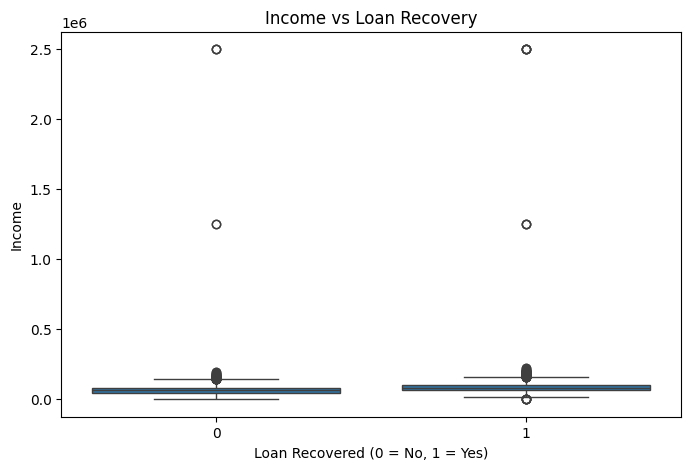

In [77]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="loan_recovered",
    y="income",
    data=df_clean
)

plt.title("Income vs Loan Recovery")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Income")

plt.show()

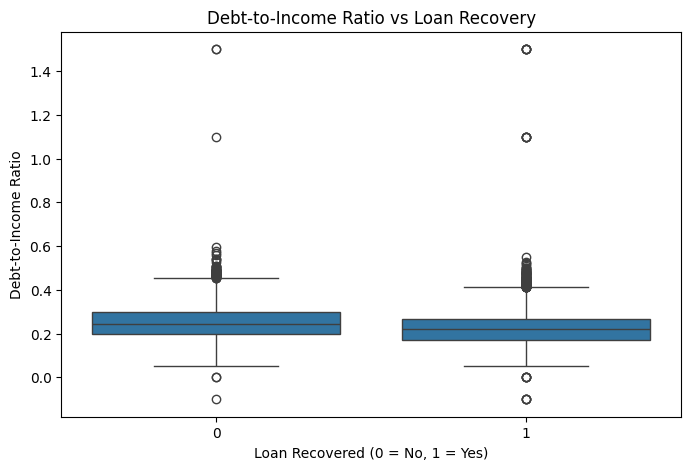

In [78]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="loan_recovered",
    y="debt_to_income",
    data=df_clean
)

plt.title("Debt-to-Income Ratio vs Loan Recovery")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Debt-to-Income Ratio")

plt.show()

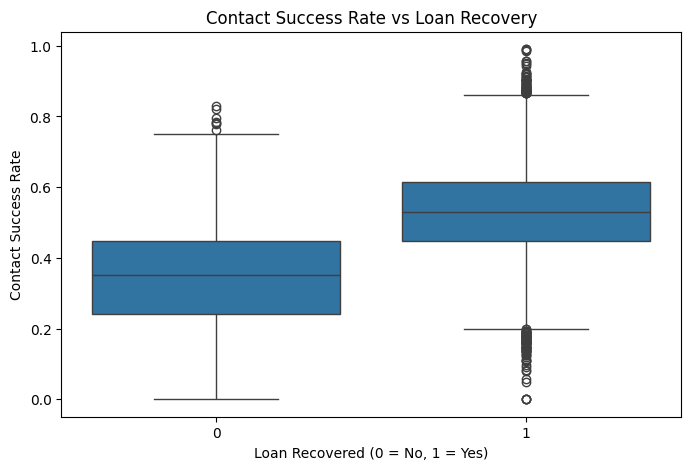

In [79]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="loan_recovered",
    y="contact_success_rate",
    data=df_clean
)

plt.title("Contact Success Rate vs Loan Recovery")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Contact Success Rate")

plt.show()

## Outlier Detection Using IQR

In [80]:
numeric_columns = [
    "age",
    "income",
    "credit_score",
    "loan_amount",
    "loan_term_months",
    "interest_rate",
    "debt_to_income",
    "existing_loans",
    "previous_defaults",
    "payment_delays",
    "employment_years",
    "collateral_value",
    "contact_success_rate"
]

for column in numeric_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]
    
    print(column, "→", len(outliers), "outliers")

age → 74 outliers
income → 213 outliers
credit_score → 234 outliers
loan_amount → 1216 outliers
loan_term_months → 0 outliers
interest_rate → 79 outliers
debt_to_income → 257 outliers
existing_loans → 85 outliers
previous_defaults → 1920 outliers
payment_delays → 1131 outliers
employment_years → 394 outliers
collateral_value → 1308 outliers
contact_success_rate → 35 outliers


## Outlier Treatment Using IQR Capping

In [81]:
outlier_columns = [
    "income",
    "loan_amount",
    "interest_rate",
    "debt_to_income",
    "collateral_value"
]

for column in outlier_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df_clean[column] = df_clean[column].clip(
        lower_bound,
        upper_bound
    )

print("Outlier capping completed.")

Outlier capping completed.


In [82]:
df_clean[outlier_columns].describe()

,income,loan_amount,interest_rate,debt_to_income,collateral_value
count,24700.000000,2.470000e+04,24700.000000,24700.000000,2.470000e+04
mean,72800.172065,5.032617e+05,8.966242,0.231747,3.435990e+05
std,30103.423600,3.037971e+05,1.196345,0.074716,3.676555e+05
min,-5000.000000,5.000000e+04,6.500000,0.031500,-5.000000e+04
25%,51000.000000,2.750000e+05,8.130000,0.180000,4.500000e+04
50%,71500.000000,4.300000e+05,8.940000,0.229000,2.100000e+05
75%,92500.000000,6.600000e+05,9.790000,0.279000,5.250000e+05
max,154750.000000,1.237500e+06,12.280000,0.427500,1.245000e+06


In [83]:
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Missing values:", df_clean.isnull().sum().sum())

Rows: 24700
Columns: 19
Missing values: 0


In [84]:
df_clean.loc[
    df_clean["income"] <= 0,
    "income"
] = np.nan

In [85]:
df_clean.loc[
    df_clean["collateral_value"] < 0,
    "collateral_value"
] = np.nan

In [86]:
df_clean.loc[
    (df_clean["credit_score"] < 300) |
    (df_clean["credit_score"] > 850),
    "credit_score"
] = np.nan

In [87]:
columns_to_impute = [
    "income",
    "collateral_value",
    "credit_score"
]

for column in columns_to_impute:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

In [88]:
print("Missing values:", df_clean.isnull().sum().sum())

print("Minimum income:", df_clean["income"].min())
print("Minimum collateral:", df_clean["collateral_value"].min())
print("Minimum credit score:", df_clean["credit_score"].min())
print("Maximum credit score:", df_clean["credit_score"].max())

Missing values: 0
Minimum income: 10000.0
Minimum collateral: 0.0
Minimum credit score: 410.0
Maximum credit score: 805.0


In [89]:
df_clean.describe()

,age,income,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,employment_years,collateral_value,contact_success_rate,loan_recovered
count,24700.000000,24700.000000,24700.000000,2.470000e+04,24700.000000,24700.000000,24700.000000,24700.000000,24700.000000,24700.000000,24700.000000,2.470000e+04,24700.000000,24700.000000
mean,37.095506,72836.730769,616.145911,5.032617e+05,42.403482,8.966242,0.231747,1.381457,0.847652,2.125061,9.913806,3.437043e+05,0.464688,0.650000
std,8.668583,30056.052227,50.189142,3.037971e+05,17.920969,1.196345,0.074716,1.242491,1.077576,2.312806,5.670899,3.675800e+05,0.161036,0.476979
min,19.000000,10000.000000,410.000000,5.000000e+04,12.000000,6.500000,0.031500,0.000000,0.000000,-2.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,31.000000,51000.000000,583.000000,2.750000e+05,36.000000,8.130000,0.180000,0.000000,0.000000,1.000000,6.000000,4.500000e+04,0.365000,0.000000
50%,37.000000,71500.000000,616.000000,4.300000e+05,36.000000,8.940000,0.229000,1.000000,1.000000,2.000000,10.000000,2.100000e+05,0.476000,1.000000
75%,43.000000,92500.000000,650.000000,6.600000e+05,60.000000,9.790000,0.279000,2.000000,1.000000,3.000000,13.000000,5.250000e+05,0.577000,1.000000
max,65.000000,154750.000000,805.000000,1.237500e+06,84.000000,12.280000,0.427500,20.000000,12.000000,40.000000,50.000000,1.245000e+06,0.990000,1.000000


## Correlation Analysis

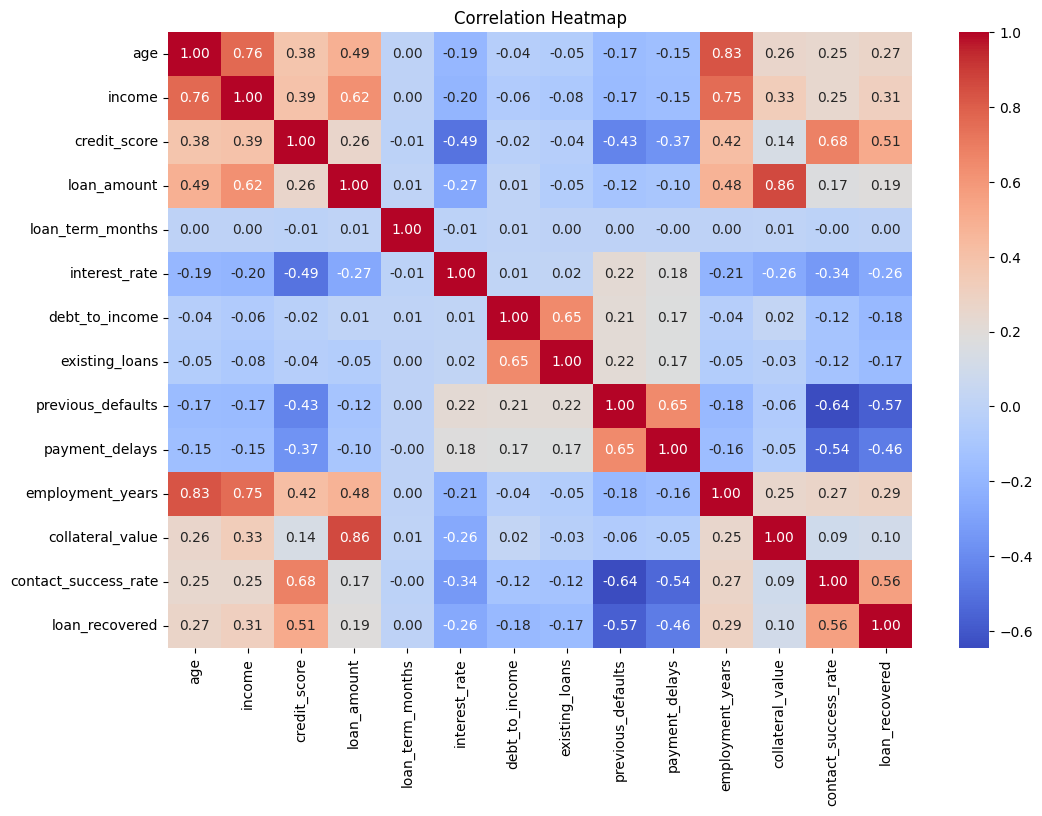

In [90]:
plt.figure(figsize=(12, 8))

correlation = df_clean.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

## Feature Selection and Target Separation

In [91]:
X = df_clean.drop(
    columns=["customer_id", "customer_name", "loan_id", "loan_recovered"]
)

y = df_clean["loan_recovered"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (24700, 15)
Target shape: (24700,)


In [92]:
print("Features:")
print(X.columns.tolist())

Features:
['age', 'income', 'employment_type', 'credit_score', 'loan_amount', 'loan_term_months', 'interest_rate', 'debt_to_income', 'existing_loans', 'previous_defaults', 'payment_delays', 'employment_years', 'collateral_value', 'loan_purpose', 'contact_success_rate']


In [93]:
print("Target:")
print(y.name)

Target:
loan_recovered


In [94]:
numeric_features = [
    "age",
    "income",
    "credit_score",
    "loan_amount",
    "loan_term_months",
    "interest_rate",
    "debt_to_income",
    "existing_loans",
    "previous_defaults",
    "payment_delays",
    "employment_years",
    "collateral_value",
    "contact_success_rate"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 13
Categorical features: 2


## Categorical Feature Encoding

In [95]:
X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True
)

print("Original feature count:", X.shape[1])
print("Encoded feature count:", X_encoded.shape[1])

Original feature count: 15
Encoded feature count: 21


In [96]:
print(X_encoded.columns.tolist())

['age', 'income', 'credit_score', 'loan_amount', 'loan_term_months', 'interest_rate', 'debt_to_income', 'existing_loans', 'previous_defaults', 'payment_delays', 'employment_years', 'collateral_value', 'contact_success_rate', 'employment_type_Contract', 'employment_type_Salaried', 'employment_type_Self-Employed', 'employment_type_Unemployed', 'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal', 'loan_purpose_Vehicle']


In [97]:
drop_first=True

In [98]:
X_encoded.head()

,age,income,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,...,collateral_value,contact_success_rate,employment_type_Contract,employment_type_Salaried,employment_type_Self-Employed,employment_type_Unemployed,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_purpose_Vehicle
0,50.0,94000.0,641.0,480000.0,48,7.84,0.302,1.0,0.0,0.0,...,355000.0,0.688,False,True,False,False,False,False,False,True
1,40.0,61000.0,545.0,155000.0,48,11.51,0.206,0.0,1.0,2.0,...,5000.0,0.400,False,True,False,False,False,False,True,False
2,60.0,141500.0,740.0,1075000.0,18,8.10,0.190,0.0,0.0,0.0,...,595000.0,0.903,False,True,False,False,False,False,False,True
3,37.0,48500.0,602.0,195000.0,18,9.33,0.275,2.0,0.0,0.0,...,135000.0,0.486,False,False,True,False,False,False,False,True
4,31.0,45000.0,669.0,220000.0,60,9.99,0.280,2.0,0.0,1.0,...,25000.0,0.506,False,True,False,False,False,False,True,False


In [99]:
print("Final feature matrix shape:", X_encoded.shape)

Final feature matrix shape: (24700, 21)


In [100]:
print("Original feature count:", X.shape[1])
print("Encoded feature count:", X_encoded.shape[1])

Original feature count: 15
Encoded feature count: 21


## Train-Test Split

In [101]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (19760, 21)
X_test: (4940, 21)
y_train: (19760,)
y_test: (4940,)


In [102]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
loan_recovered
1    65.0
0    35.0
Name: proportion, dtype: float64

Testing target distribution:
loan_recovered
1    65.0
0    35.0
Name: proportion, dtype: float64


## Feature Scaling

In [103]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (19760, 21)
Testing data shape: (4940, 21)


## Logistic Regression Model

In [104]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [105]:
y_pred_lr = logistic_model.predict(X_test_scaled)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred_lr))

Predictions generated successfully!
Number of predictions: 4940


## Logistic Regression Evaluation

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm_lr)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Not Recovered", "Recovered"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [106]:
from sklearn.metrics import recall_score

recall_lr = recall_score(y_test, y_pred_lr)

print("Logistic Regression Recall:", recall_lr)

Logistic Regression Recall: 0.9140454687013392


In [107]:
from sklearn.metrics import roc_auc_score

y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression ROC-AUC:", roc_auc_lr)

Logistic Regression ROC-AUC: 0.9180502822588416


In [108]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Not Recovered", "Recovered"]
))

Logistic Regression Classification Report:
               precision    recall  f1-score   support

Not Recovered       0.82      0.72      0.76      1729
    Recovered       0.86      0.91      0.88      3211

     accuracy                           0.85      4940
    macro avg       0.84      0.82      0.82      4940
 weighted avg       0.84      0.85      0.84      4940



## Decision Tree Model

A Decision Tree is a supervised learning algorithm that makes predictions
by splitting the data based on feature values.

It is easy to interpret and can capture non-linear relationships between
customer characteristics and loan recovery.

## Decision Tree Model

A Decision Tree is a supervised learning algorithm that makes predictions
by splitting the data based on feature values.

It is easy to interpret and can capture non-linear relationships between
customer characteristics and loan recovery.

In [109]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=6
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [110]:
y_pred_dt = decision_tree_model.predict(X_test)

print("Decision Tree predictions generated successfully!")
print("Number of predictions:", len(y_pred_dt))

Decision Tree predictions generated successfully!
Number of predictions: 4940


Decision Tree Confusion Matrix:
[[1199  530]
 [ 287 2924]]


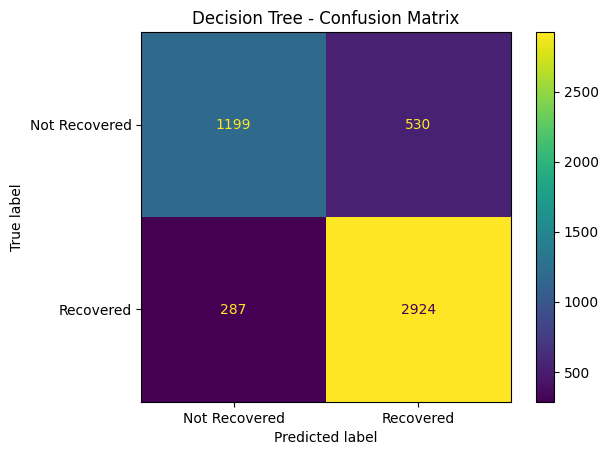

In [111]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Not Recovered", "Recovered"]
).plot()

plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [112]:
from sklearn.metrics import recall_score

recall_dt = recall_score(y_test, y_pred_dt)

print("Decision Tree Recall:", recall_dt)

Decision Tree Recall: 0.9106197446278418


In [113]:
from sklearn.metrics import roc_auc_score

y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree ROC-AUC:", roc_auc_dt)

Decision Tree ROC-AUC: 0.8985512676115703


In [114]:
from sklearn.metrics import classification_report

print("Decision Tree Classification Report:")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["Not Recovered", "Recovered"]
))

Decision Tree Classification Report:
               precision    recall  f1-score   support

Not Recovered       0.81      0.69      0.75      1729
    Recovered       0.85      0.91      0.88      3211

     accuracy                           0.83      4940
    macro avg       0.83      0.80      0.81      4940
 weighted avg       0.83      0.83      0.83      4940



## Random Forest Model

Random Forest is an ensemble learning algorithm that combines multiple
Decision Trees to make a more reliable prediction.

It generally provides better performance and reduces overfitting compared
with using a single Decision Tree.

In [115]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=8
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [116]:
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest predictions generated successfully!")
print("Number of predictions:", len(y_pred_rf))

Random Forest predictions generated successfully!
Number of predictions: 4940


Random Forest Confusion Matrix:
[[1195  534]
 [ 262 2949]]


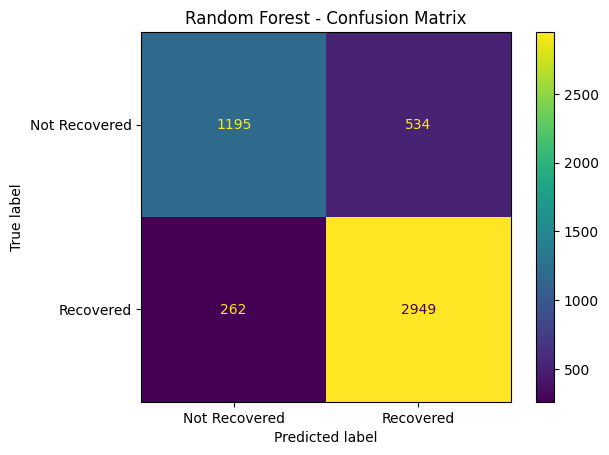

In [117]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Not Recovered", "Recovered"]
).plot()

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [118]:
from sklearn.metrics import recall_score

recall_rf = recall_score(y_test, y_pred_rf)

print("Random Forest Recall:", recall_rf)

Random Forest Recall: 0.9184054811585176


In [119]:
from sklearn.metrics import roc_auc_score

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest ROC-AUC: 0.9134364791071179


In [120]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report:")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Not Recovered", "Recovered"]
))

Random Forest Classification Report:
               precision    recall  f1-score   support

Not Recovered       0.82      0.69      0.75      1729
    Recovered       0.85      0.92      0.88      3211

     accuracy                           0.84      4940
    macro avg       0.83      0.80      0.82      4940
 weighted avg       0.84      0.84      0.84      4940



## ROC Curve Comparison

The ROC curve shows the relationship between the True Positive Rate
and False Positive Rate at different classification thresholds.

ROC-AUC summarizes the overall ability of each model to distinguish
between recovered and non-recovered loans.

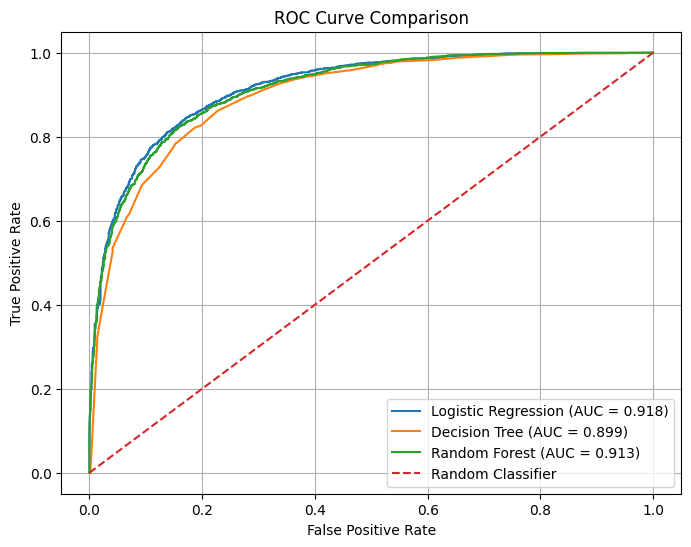

In [121]:
from sklearn.metrics import roc_curve

# Calculate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc_lr:.3f})"
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {roc_auc_dt:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_rf:.3f})"
)

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

## Explainable AI - Random Forest Feature Importance

Random Forest provides feature importance scores that show the relative
contribution of each feature to the model's predictions.

This helps us understand which factors are most influential in predicting
loan recovery and can support debt recovery strategies.

In [122]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
8,previous_defaults,0.303841
12,contact_success_rate,0.202077
2,credit_score,0.179941
9,payment_delays,0.107626
1,income,0.050238
10,employment_years,0.032161
0,age,0.022678
6,debt_to_income,0.021192
5,interest_rate,0.020991
3,loan_amount,0.015460


## Top Features Influencing Loan Recovery

The feature importance visualization highlights the variables that have
the greatest influence on the Random Forest model's predictions.

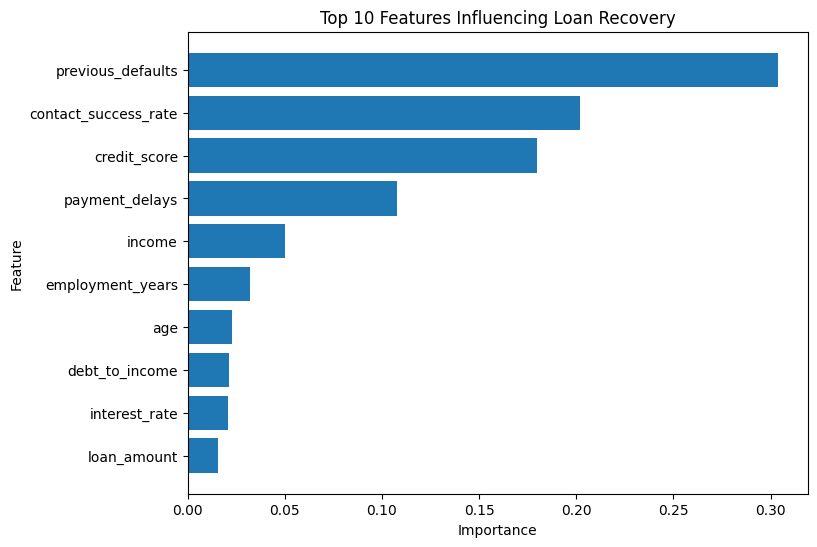

In [123]:
plt.figure(figsize=(8, 6))

top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Influencing Loan Recovery")

plt.show()

In [124]:
!pip install shap

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [125]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP imported successfully!")

C:\Users\manth\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.52.0
SHAP imported successfully!


In [126]:
explainer = shap.TreeExplainer(random_forest_model)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [127]:
shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


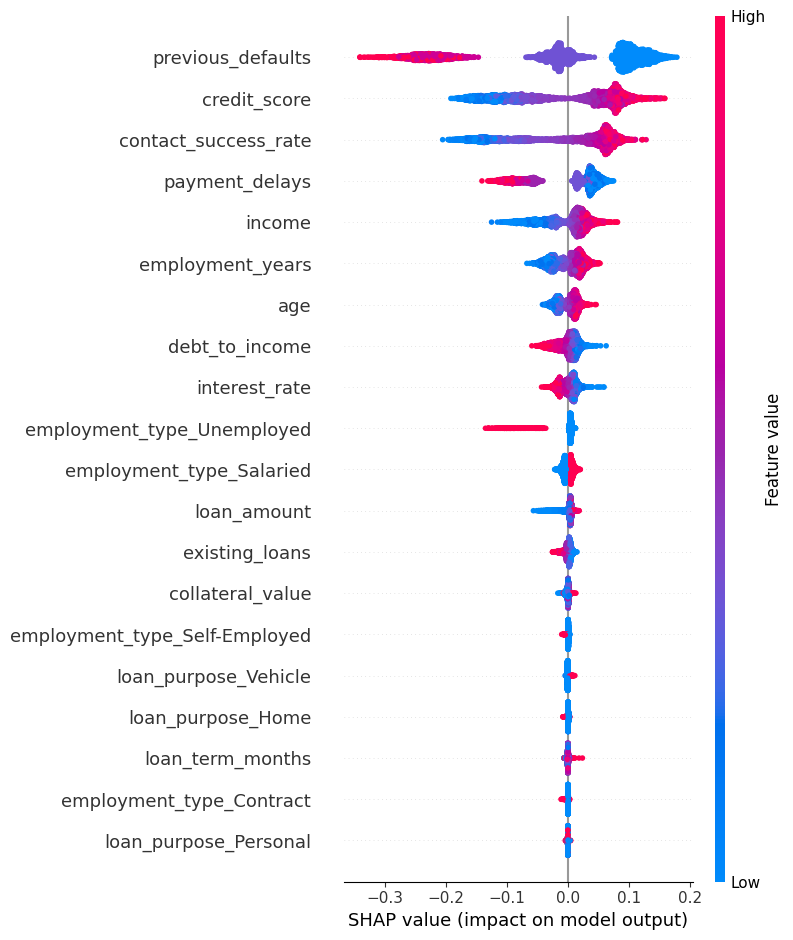

In [128]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test,
    show=True
)

### SHAP Insights

The SHAP analysis provides both feature importance and the direction of
feature influence on loan recovery predictions.

The results show that previous defaults and payment delays generally push
predictions toward non-recovery, while higher credit scores and higher
contact success rates generally push predictions toward recovery.

These insights can be used to design targeted debt recovery strategies.

## Debt Recovery Strategy

The machine learning and explainability results can be used to segment
customers and prioritize recovery efforts.

Customers with higher recovery likelihood can be handled using
standardized and lower-cost communication methods, while customers with
lower recovery likelihood can receive more proactive and personalized
follow-up.

The strategy is based on model predictions and the factors identified
through feature importance and SHAP analysis.

In [129]:
recovery_probability = random_forest_model.predict_proba(X_test)[:, 1]

recovery_segments = pd.DataFrame({
    "Actual": y_test.values,
    "Recovery_Probability": recovery_probability
})

recovery_segments["Segment"] = pd.cut(
    recovery_segments["Recovery_Probability"],
    bins=[0, 0.40, 0.70, 1.00],
    labels=["Low Recovery", "Medium Recovery", "High Recovery"]
)

recovery_segments["Segment"].value_counts()

Segment
High Recovery      2782
Low Recovery       1188
Medium Recovery     970
Name: count, dtype: int64

In [130]:
segment_recovery = recovery_segments.groupby(
    "Segment",
    observed=True
)["Actual"].mean() * 100

print("Recovery Rate by Segment:")
print(segment_recovery)

Recovery Rate by Segment:
Segment
Low Recovery       13.215488
Medium Recovery    52.268041
High Recovery      91.552840
Name: Actual, dtype: float64


## Recommended Debt Recovery Strategy

Based on the model's predicted recovery probability and SHAP insights,
customers can be prioritized into three recovery segments.

### Low Recovery
Customers with predicted recovery probability below 40%.

**Recommended approach:**
- High-priority follow-up
- Personalized communication
- Review previous defaults and payment delays
- Consider suitable repayment assistance where appropriate

### Medium Recovery
Customers with predicted recovery probability between 40% and 70%.

**Recommended approach:**
- Regular follow-up
- Payment reminders
- Monitor payment behavior
- Encourage timely repayment

### High Recovery
Customers with predicted recovery probability above 70%.

**Recommended approach:**
- Standard reminders
- Lower-cost communication
- Automated follow-up
- Focus intensive recovery resources elsewhere

## Final Model Selection

After comparing Logistic Regression, Decision Tree, and Random Forest,
Random Forest was selected as the final model.

It achieved the highest recall of 91.87%, while maintaining a strong
ROC-AUC of 91.35%.

Recall is emphasized because correctly identifying recovered loans is
an important objective of this project.

In [131]:
final_model = random_forest_model

print("Final model selected: Random Forest")
print("Recall:", recall_rf)
print("ROC-AUC:", roc_auc_rf)

Final model selected: Random Forest
Recall: 0.9184054811585176
ROC-AUC: 0.9134364791071179


In [132]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

model_data = {
    "model": final_model,
    "feature_columns": X_train.columns.tolist()
}

joblib.dump(
    model_data,
    "../models/loan_recovery_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [133]:
saved_model = joblib.load("../models/loan_recovery_model.pkl")

print("Saved model loaded successfully!")
print("Number of features:", len(saved_model["feature_columns"]))
print("Model type:", type(saved_model["model"]).__name__)

Saved model loaded successfully!
Number of features: 21
Model type: RandomForestClassifier
